Numerical intensity at z=0: 0.999763, Theoretical: 1.000000, Absolute Error: 2.369109e-04
Numerical intensity at z=z_R: 0.497950, Theoretical: 0.500000, Absolute Error: 2.049789e-03
Numerical intensity at z=2*z_R: 0.199672, Theoretical: 0.200000, Absolute Error: 3.282944e-04
Numerical intensity at z=3*z_R: 0.099998, Theoretical: 0.100000, Absolute Error: 2.008004e-06


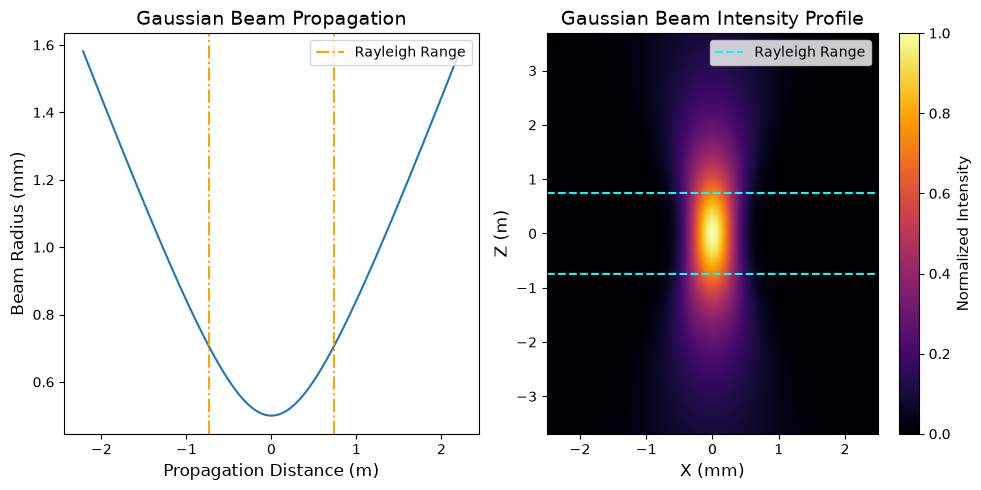

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

#parameters
labda = 1064e-9  # Wavelength in meters
w0 = 0.5e-3  # Beam waist in meters
I0 = 1.0

#rayleigh and propagation range
z_R = np.pi * w0**2 / labda
z = np.linspace(-3*z_R, 3*z_R, 500)

# Create a grid of points
x = np.linspace(-5*w0, 5*w0, 500)
#y = np.linspace(-3*w0, 3*w0, 500)
X, Z = np.meshgrid(x, z)

#Beam radius
w_z = w0 * np.sqrt(1 + (z/ z_R)**2)
w_z_I = w0 * np.sqrt(1 + (Z/ z_R)**2)

# Far field divergence angle
theta = labda / (np.pi * w0)

# Create a Gaussian beam intensity profile
I = I0*(w0 / w_z_I)**2 * np.exp(-2 *X**2/ w_z_I**2)

# Normalize the intensity for visualization
I_norm = I / np.max(I)

fig, ax = plt.subplots(1,2, figsize=(10, 5))
# Plot the beam radius as a function of propagation distance
ax[0].plot(z, w_z*1e3)
ax[0].set_xlabel("Propagation Distance (m)", fontsize=12)
ax[0].set_ylabel("Beam Radius (mm)", fontsize=12)
ax[0].set_title("Gaussian Beam Propagation", fontsize=14)

# mark the Rayleigh range on the plot
ax[0].axvline(x=z_R, color='orange', linestyle='-.', label='Rayleigh Range')
ax[0].axvline(x=-z_R, color='orange', linestyle='-.')
ax[0].legend(loc='upper right', fontsize=10)

# Plot the normalized Two-dimensional intensity distribution
im = ax[1].imshow(I_norm, extent=[-5*w0*1e3, 5*w0*1e3, -5*z_R, 5*z_R], origin='lower',
             cmap='inferno', vmin=0, vmax=1, aspect='auto',)
ax[1].set_title("Gaussian Beam Intensity Profile", fontsize=14)
ax[1].set_xlabel("X (mm)", fontsize=12)
ax[1].set_ylabel("Z (m)", fontsize=12)

# Colorbar
cbar = fig.colorbar(im, ax=ax[1])
cbar.set_label("Normalized Intensity", fontsize=11)




# On-axis intensity
index_z0 = np.argmin(np.abs(z - 0))
index_z1 = np.argmin(np.abs(z - z_R))
index_z2 = np.argmin(np.abs(z - 2*z_R))
index_z3 = np.argmin(np.abs(z - 3*z_R))
index_x0 = np.argmin(np.abs(x - 0))
I_on_axis_z0 = I[index_z0, index_x0]
I_on_axis_z1 = I[index_z1, index_x0]
I_on_axis_z2 = I[index_z2, index_x0]
I_on_axis_z3 = I[index_z3, index_x0]

# Print the on-axis intensity values
#print("On-axis intensity at z=0: ", I_on_axis_z0)
#print("On-axis intensity at z=z_R: ", I_on_axis_z1)
#print("On-axis intensity at z=2*z_R: ", I_on_axis_z2)
#print("On-axis intensity at z=3*z_R: ", I_on_axis_z3)

# Calculate the absolute error between the calculated and theoretical on-axis intensity values
error_z0 = np.abs(I_on_axis_z0 - I0)
error_z1 = np.abs(I_on_axis_z1 - I0/2)
error_z2 = np.abs(I_on_axis_z2 - I0/5)
error_z3 = np.abs(I_on_axis_z3 - I0/10)
print(f"Numerical intensity at z=0: {I_on_axis_z0:.6f}, Theoretical: {I0:.6f}, Absolute Error: {error_z0:.6e}")
print(f"Numerical intensity at z=z_R: {I_on_axis_z1:.6f}, Theoretical: {I0/2:.6f}, Absolute Error: {error_z1:.6e}")
print(f"Numerical intensity at z=2*z_R: {I_on_axis_z2:.6f}, Theoretical: {I0/5:.6f}, Absolute Error: {error_z2:.6e}")
print(f"Numerical intensity at z=3*z_R: {I_on_axis_z3:.6f}, Theoretical: {I0/10:.6f}, Absolute Error: {error_z3:.6e}")

# mark the Rayleigh range on the intensity profile
ax[1].axhline(y=z_R, color='cyan', linestyle='--', label='Rayleigh Range')
ax[1].axhline(y=-z_R, color='cyan', linestyle='--')
ax[1].legend(loc='upper right', fontsize=10)

plt.tight_layout()
# save the figure in different formats
fig.savefig("gaussian_beam.png", dpi=300)
fig.savefig("gaussian_beam.pdf", bbox_inches="tight")
fig.savefig("gaussian_beam.svg", bbox_inches="tight")

plt.show()

In [161]:
from PIL import Image

img = Image.open("elliptical_gaussian.png")
print(img.size)

(2400, 1800)


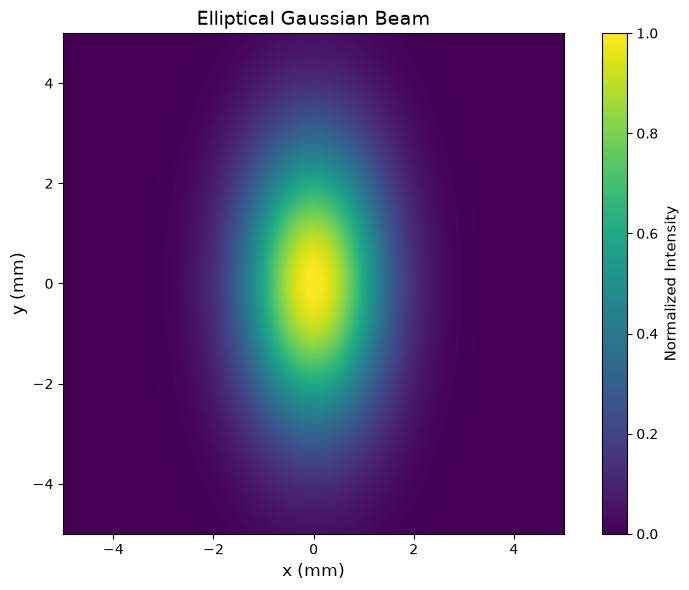

In [160]:
import numpy as np
import matplotlib.pyplot as plt

# Spatial coordinates (mm)
x = np.linspace(-5, 5, 200)
y = np.linspace(-5, 5, 200)

X, Y = np.meshgrid(x, y)

# Beam parameters
wx = 2.0
wy = 4.0

# Gaussian intensity distribution
I = np.exp(
    -2 * ((X / wx)**2 + (Y / wy)**2)
)

# Normalize intensity
I_norm = I / np.max(I)

# Create figure and axes
fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    I_norm,
    origin="lower",
    extent=[-5, 5, -5, 5],
    cmap="viridis",
    vmin=0,
    vmax=1
)

# Scientific formatting
ax.set_xlabel("x (mm)", fontsize=12)
ax.set_ylabel("y (mm)", fontsize=12)
ax.set_title("Elliptical Gaussian Beam", fontsize=14)

ax.set_aspect("equal")
ax.tick_params(axis="both", labelsize=10)

# Colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Normalized Intensity", fontsize=11)

fig.tight_layout()

# save the figure in different formats
fig.savefig("elliptical_gaussian.png", dpi=300)
fig.savefig("elliptical_gaussian.pdf", bbox_inches="tight")
fig.savefig("elliptical_gaussian.svg", bbox_inches="tight")

plt.show()

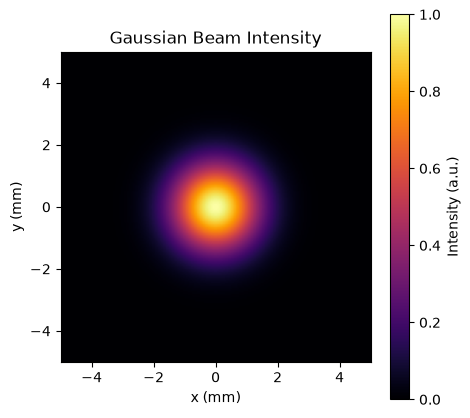

In [154]:
import matplotlib.pyplot as plt
import numpy as np

# Gaussian beam parameters
I0 = 1.0
w = 2.0  # Beam radius in mm
#wx = 4.0  # Beam radius along x (mm)
#wy = 2.0  # Beam radius along y (mm)

# Spatial coordinates (mm)
x = np.linspace(-5, 5, 200)
y = np.linspace(-5, 5, 200)

X, Y = np.meshgrid(x, y)

# Gaussian intensity
I = I0 * np.exp(
    -2 * ((X)**2 + (Y)**2)/w**2
)
I_norm = I0 * np.exp(
    -2 * ((X)**2 + (Y)**2)/w**2/np.max(I)
)

fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(
    I_norm,
    origin="lower",
    cmap="inferno",
    extent=[-5, 5, -5, 5],
    vmin = 0, vmax = 1
)

fig.colorbar(im, ax=ax, label="Intensity (a.u.)")

ax.set_xlabel("x (mm)")
ax.set_ylabel("y (mm)")
ax.set_title("Gaussian Beam Intensity")

plt.show()

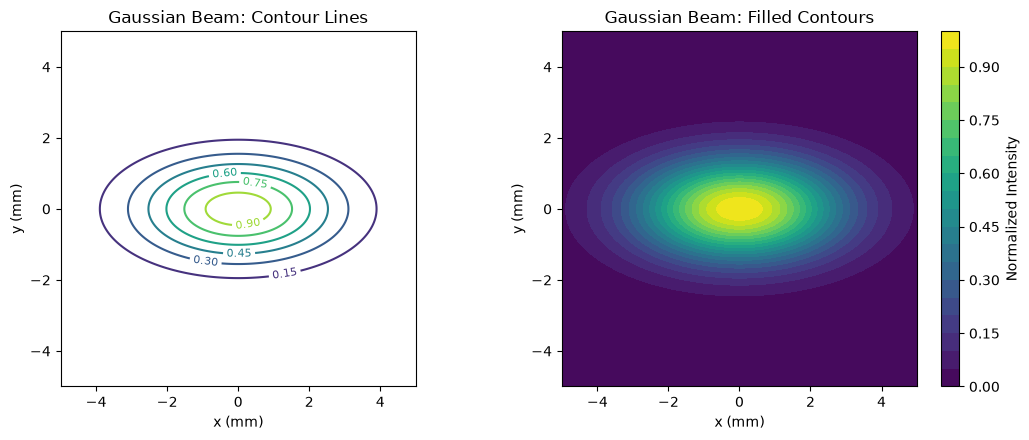

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Gaussian beam parameters
I0 = 1.0
#w = 2.0  # Beam radius in mm
wx = 4.0  # Beam radius along x (mm)
wy = 2.0  # Beam radius along y (mm)


# Spatial coordinates (mm)
x = np.linspace(-5, 5, 200)
y = np.linspace(-5, 5, 200)

X, Y = np.meshgrid(x, y)

# Gaussian intensity
I = I0 * np.exp(
    -2 * ((X / wx)**2 + (Y / wy)**2)
)

#I = I0 * np.exp(-2 * (X**2 + Y**2) / w**2)

# Create two subplots
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Contour lines
cs = axes[0].contour(X, Y, I, levels=8, cmap="viridis")
axes[0].clabel(cs, inline=True, fontsize=8)
axes[0].set_title("Gaussian Beam: Contour Lines")

# Filled contours
cf = axes[1].contourf(X, Y, I, levels=20, cmap="viridis")
fig.colorbar(cf, ax=axes[1], label="Normalized Intensity")
axes[1].set_title("Gaussian Beam: Filled Contours")

for ax in axes:
    ax.set_xlabel("x (mm)")
    ax.set_ylabel("y (mm)")
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

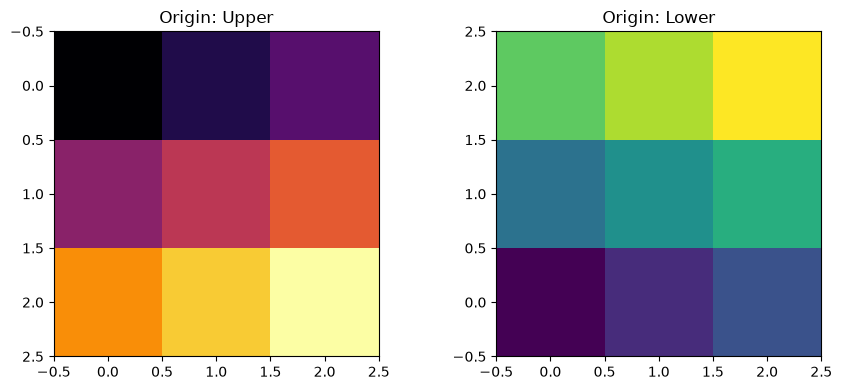

In [129]:
import numpy as np
import matplotlib.pyplot as plt

I = np.array([
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9]
])

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(I, origin="upper", cmap="inferno")
axes[0].set_title("Origin: Upper")

axes[1].imshow(I, origin="lower", cmap="viridis")
axes[1].set_title("Origin: Lower")

plt.tight_layout()
plt.show()

Type1
Fairy        2
Ice          2
Ghost        3
Dragon       3
Fighting     7
Psychic      7
Ground       8
Electric     9
Rock         9
Grass       12
Fire        12
Bug         12
Poison      14
Normal      22
Water       28
Name: count, dtype: int64


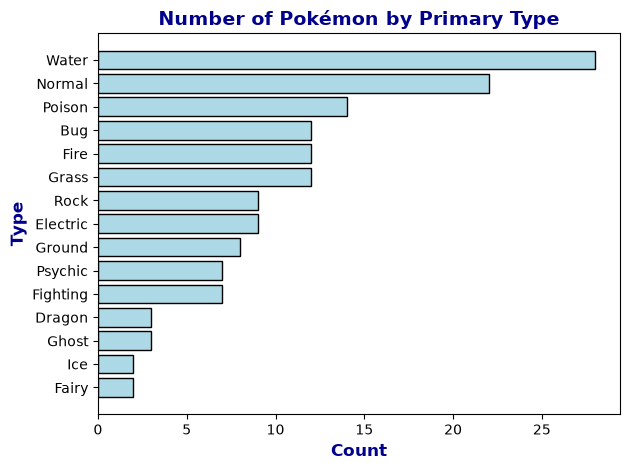

In [130]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
df = pd.read_csv('data.csv')

type_count = df['Type1'].value_counts(ascending = True)
plt.barh(type_count.index, type_count.values, color='lightblue', edgecolor='black')
plt.title('Number of Pokémon by Primary Type', fontsize=14, fontweight='bold', color='darkblue')
plt.xlabel('Count', fontsize=12, fontweight='bold', color='darkblue')
plt.ylabel('Type', fontsize=12, fontweight='bold', color='darkblue')
print(type_count)
plt.tight_layout()
plt.show()

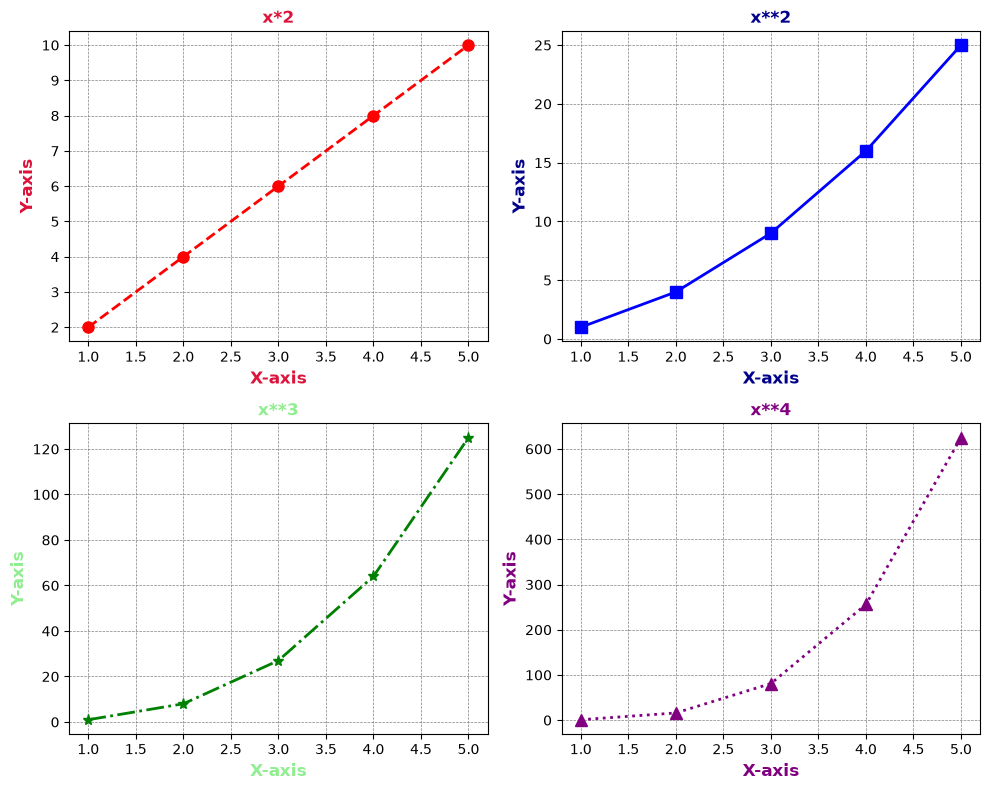

In [131]:
import matplotlib.pyplot as plt
import numpy as np
x = np.array([1, 2, 3, 4, 5])
figure, axes = plt.subplots(2, 2,figsize=(10, 8))
for ax in axes.flat:
    ax.grid(True, which='both', linestyle='--', linewidth=0.5, color='gray')
axes[0, 0].plot(x, x*2, color='red', marker='o', linestyle='--', linewidth=2, markersize=8)
axes[0, 0].set_xlabel('X-axis', fontsize=12, fontweight='bold', color='crimson')
axes[0, 0].set_ylabel('Y-axis', fontsize=12, fontweight='bold', color='crimson')
axes[0,0].set_title('x*2', fontsize=12, fontweight='bold', color='crimson')

axes[0, 1].plot(x, x**2, color='blue', marker='s', linestyle='-', linewidth=2, markersize=8)
axes[0, 1].set_title('x**2', fontsize=12, fontweight='bold', color='darkblue')
axes[0, 1].set_xlabel('X-axis', fontsize=12, fontweight='bold', color='darkblue')
axes[0, 1].set_ylabel('Y-axis', fontsize=12, fontweight='bold', color='darkblue')

axes[1, 0].plot(x, x**3, color='green', marker='*', linestyle='-.', linewidth=2, markersize=8)
axes[1, 0].set_xlabel('X-axis', fontsize=12, fontweight='bold', color='lightgreen')
axes[1, 0].set_ylabel('Y-axis', fontsize=12, fontweight='bold', color='lightgreen')
axes[1,0].set_title('x**3', fontsize=12, fontweight='bold', color='lightgreen')

axes[1, 1].plot(x, x**4, color='purple', marker='^', linestyle=':', linewidth=2, markersize=8)
axes[1, 1].set_xlabel('X-axis', fontsize=12, fontweight='bold', color='purple')
axes[1, 1].set_ylabel('Y-axis', fontsize=12, fontweight='bold', color='purple')
axes[1, 1].set_title('x**4', fontsize=12, fontweight='bold', color='purple')

plt.tight_layout()
plt.show()

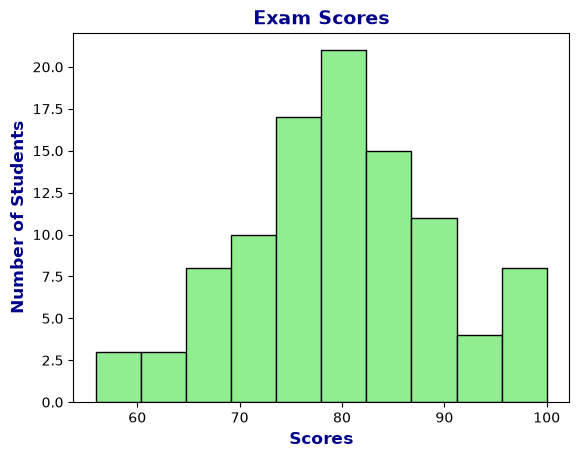

In [132]:
import matplotlib.pyplot as plt
import numpy as np
scores = np.random.normal(loc=80, scale=10, size=100)
scores = np.clip(scores, 0, 100)  # Ensure scores are between 0 and 100
plt.hist(scores, bins=10,color = 'lightgreen', edgecolor='black')
plt.title('Exam Scores', fontsize=14, fontweight='bold', color='darkblue')
plt.xlabel('Scores', fontsize=12, fontweight='bold', color='darkblue')
plt.ylabel('Number of Students', fontsize=12, fontweight='bold', color='darkblue')
plt.show()

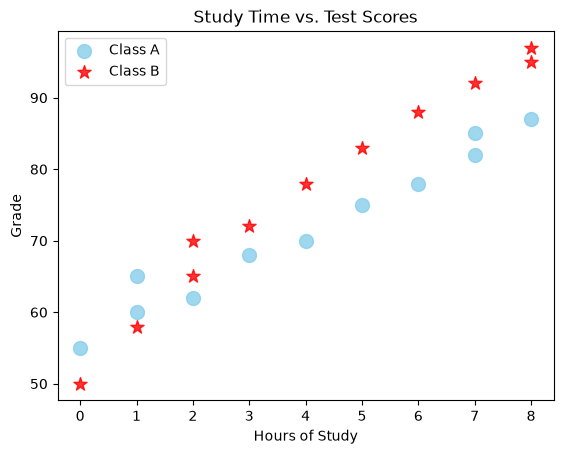

In [133]:
import matplotlib.pyplot as plt
import numpy as np
x1 = np.array([0, 1, 1,2,3,4,5,6,7, 7,8])
y1= np.array([55, 60, 65, 62, 68, 70, 75, 78, 82, 85, 87])
x2 = np.array([0, 1, 2,2,3,4,5,6,7, 8,8])
y2= np.array([50, 58, 65, 70, 72, 78, 83, 88, 92, 95, 97])
plt.scatter(x1, y1, color = 'skyblue', alpha = 0.8, s = 100, marker = 'o', label = 'Class A')
plt.scatter(x2, y2, color = 'red', alpha = 0.8, s = 100, marker = '*', label = 'Class B')
plt.xlabel('Hours of Study')
plt.ylabel('Grade')
plt.title('Study Time vs. Test Scores')
plt.legend()
plt.show()


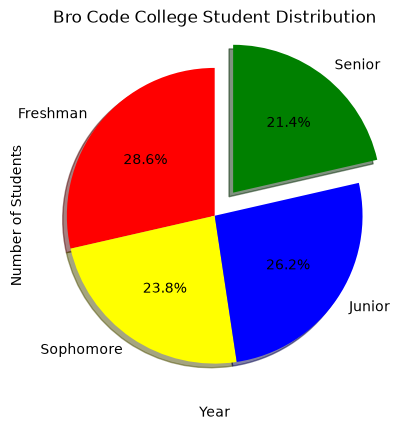

In [134]:
import matplotlib.pyplot as plt
import numpy as np
categories = ['Freshman', 'Sophomore', 'Junior', 'Senior']
values = np.array([300, 250, 275, 225])
colors = ['red', 'yellow', 'blue', 'green']
plt.pie(values, labels=categories, autopct='%1.1f%%', colors=colors, 
        explode=(0, 0, 0, 0.2), shadow=True, startangle=90)
plt.title('Bro Code College Student Distribution')
plt.xlabel('Year')
plt.ylabel('Number of Students')
plt.show()

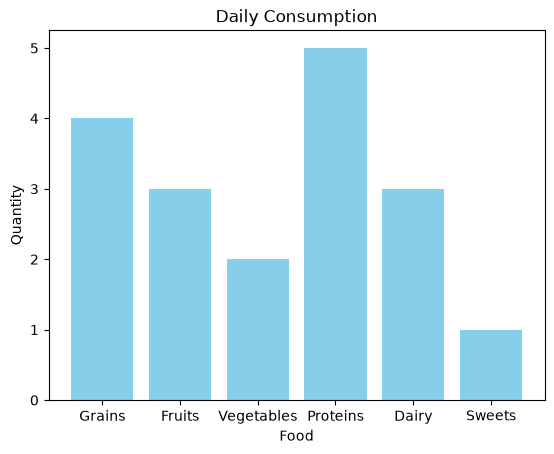

In [135]:
import matplotlib.pyplot as plt
import numpy as np
categories = np.array(['Grains', 'Fruits', 'Vegetables', 'Proteins', 'Dairy', 'Sweets'])
values = np.array([4, 3, 2, 5, 3, 1])
plt.bar(categories, values, color = 'skyblue')
#plt.barh(categories, values, color = 'skyblue')
plt.title('Daily Consumption')
plt.xlabel('Food')
plt.ylabel('Quantity')
#x = [1,2, 3,4,5]
#y = [5,10,15,20,25]
#plt.plot(x,y)
#plt.grid(axis = 'both', linewidth = 0.5, color = 'lightgray', linestyle = 'solid')
plt.show()

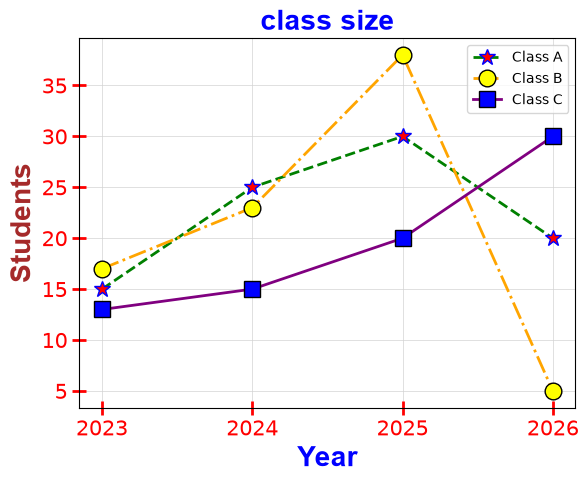

In [136]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
x = np.array([2023, 2024, 2025, 2026])
y1 = np.array([15, 25, 30, 20])
y2 = np.array([17, 23, 38, 5])
y3 = np.array([13, 15, 20, 30])
plt.grid(axis = 'both', linewidth = 0.5, color = 'lightgray', linestyle = 'solid')
plt.plot(x,y1, label="Class A", marker = '*', markersize = 12, markerfacecolor = 'red',
          markeredgecolor = 'blue',
          linestyle = '--', linewidth = 2, color = 'green')
plt.plot(x,y2, label="Class B", marker = 'o', markersize = 12, markerfacecolor = 'yellow',
          markeredgecolor = 'black',
          linestyle = '-.', linewidth = 2, color = 'orange')
plt.plot(x,y3, label="Class C", marker = 's', markersize = 12, markerfacecolor = 'blue',
          markeredgecolor = 'black',
          linestyle = 'solid', linewidth = 2, color = 'purple')
plt.xlabel('Year', fontsize = 20, family = 'Arial', color = 'blue', fontweight = 'bold')
plt.ylabel('Students', fontsize = 20, family = 'Arial', color = 'brown', fontweight = 'bold')
plt.title('class size', fontsize = 20, family = 'Arial', color = 'blue', fontweight = 'bold')
plt.tick_params(axis = 'both', labelsize = 15, colors = 'red', direction = 'inout', length = 10, width = 2)
plt.xticks(x)
plt.legend()
plt.show()
